# Homework 3 (Hard deadline: 6.12.2026 22:00)




## AI can be used, but must be reported.
## AI shall not be used to complete the whole assignment.

## Learning Objectives
- Read and inspect raw data

- Clean and prepare data

- Descriptive and summary statistics

- Scale numerical variables

- Create visualizations

- Draw conclusions from data

- Typical data management process



## Typical Data Management Process
1. Acquire / read the data

2. Inspect and understand the data

3. Assess data quality

4. Clean the data

5. Transform and prepare the data

6. Explore and analyze the data

7. Visualize the data

8. Interpret results

9. Communicate findings

10. Store and share the prepared data

While doing this homework, think, which step of the data management process the task is related to.

## Scenario

You work for a taxi company.

The management team wants to better understand:
- trip durations
- average fares and distances
- number of trips

Your task is to clean the data, analyze it, visualize key findings, and report your conclusions.

## General Instructions
- Use the sns `taxis` dataset
- Read it first in Pandas DataFrame and then complete the tasks.
- Remember to comment your code, good policy is to have at least a short comment in every code cell.
- Add code cells when necessary.
- Good policy is to do one or few related operations in one code cell (e.g. read csv and check how it looks like in one cell and then e.g. df.info() in another etc.).
- Max points: 19

## Task 1: Load and Inspect the Data (2 points)

- Load the `taxis` dataset using Seaborn.
- Display head and tail.
- Investigate shape, columns, dtypes and info.
- Calculate missing values using isna and sum.
- Find the feature containing most missing values.
- Identify categorical, numerical and datetype variables.
- Answer the questions.

**Assessment guide for task 1:**
- 0 points: not done or less than half done
- 1 point: not completely done but more than half done
- 2 points: completely done

In [266]:
# YOUR CODE HERE; ADD MORE CODE CELLS WHEN NEEDED
# Import necessary libraries
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler 
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression

In [267]:
# Load the dataset
taxis = sns.load_dataset('taxis')

# Display head and tails
taxis.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [268]:
# Display tails
taxis.tail()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn
6432,2019-03-13 19:31:22,2019-03-13 19:48:02,1,3.85,15.0,3.36,0.0,20.16,green,credit card,Boerum Hill,Windsor Terrace,Brooklyn,Brooklyn


In [269]:
# Investigate for the shape, columns, dtypes and information of the dataset
print(f"Shape: {taxis.shape}\r\n")
print(f"Columns: {list(taxis.columns)}\r\n")
print(f"Dtypes: \r\n{taxis.dtypes}\r\n")
print(f"Information: \r\n{taxis.info()}")

Shape: (6433, 14)

Columns: ['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls', 'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough']

Dtypes: 
pickup             datetime64[us]
dropoff            datetime64[us]
passengers                  int64
distance                  float64
fare                      float64
tip                       float64
tolls                     float64
total                     float64
color                         str
payment                       str
pickup_zone                   str
dropoff_zone                  str
pickup_borough                str
dropoff_borough               str
dtype: object

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime6

In [270]:
# Calculate the missing values using isna and sum
taxis_missing_values = taxis.isna().sum()
print(f"Missing values:\r\n{taxis_missing_values}")

Missing values:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [271]:
# Accprding to the result above, the features with missing values are: 

# payment            44
# pickup_zone        26
# dropoff_zone       45
# pickup_borough     26
# dropoff_borough    45

In [272]:
# According to the result aboce, here is the data type table of the dataset:

# pickup             datetime64[us]
# dropoff            datetime64[us]
# passengers                  int64
# distance                  float64
# fare                      float64
# tip                       float64
# tolls                     float64
# total                     float64
# color                         str
# payment                       str
# pickup_zone                   str
# dropoff_zone                  str
# pickup_borough                str
# dropoff_borough               str

### My Assessment: 2 points (completed and done)

### Task 1 questions
Answer these questions:
1. How many rows and columns are in the dataset?

2. Which variables contain missing values?

3. Which variable has the most missing values?

4. Which variables are categorical?

5. Which variables are numerical?

6. Which variables appear to be datetime variables?

### My answers:

1. The dataframe has **6433** rows, an total **14** columns.
2. These columns below contain missing values: 
   - payment, 
   - pickup_zone, 
   - dropoff_zone, 
   - pickup_borough, 
   - dropoff_borough.
3. Te variable **dropoff_borough** has the most missing values (45 missing values).
4. These variables are categorical: 
   - color, 
   - payment, 
   - pickup_zone, 
   - dropoff_zone, 
   - pickup_borough, 
   - dropoff_borough.
5. These variables are numerical: 
   - passengers, 
   - distance, 
   - fare, 
   - tip, 
   - tolls, 
   - total.
6. These variables appear to be datetime variables: 
   - pickup, 
   - dropoff.

## Task 2: Data Cleaning (2 points)

- Check duplicates using *duplicated* and *sum*.
- Drop rows with missing values and check what happened.

**Assessment guide for task 2:**
- 0 points: not done or less than half done
- 1 point: not completely done but more than half done
- 2 points: completely done

In [273]:
# YOUR CODE HERE; ADD MORE CODE CELLS WHEN NEEDED
# Checking for duplicated rows
taxis_duplicated_rows = taxis.duplicated().sum()
print(f"Duplicated rows: {taxis_duplicated_rows}")

# The output is no duplicated rows in the dataset.

Duplicated rows: 0


In [274]:
# Drop missing values from the dataset
taxis.dropna(inplace=True)
print(f"Verify missing values: \r\n{taxis.isna().sum()}")

Verify missing values: 
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


### My assessment: 2 points (completed all)

## Task 3: Descriptive Statistics (2 points)

- Use describe() and investigate distance and fare. Determine mean, median, minimum, maximum and standard deviation.

- Check if the fare appears normally distributed and compare its mean and median.

  **Hint**: to check normality, use a plot (find out, which plot).

- Answer the questions.

**Assessment guide for task 1:**
- 0 points: not done or less than half done
- 1 point: not completely done but more than half done
- 2 points: completely done

In [275]:
# YOUR CODE HERE; ADD MORE CODE CELLS WHEN NEEDED
# Descriptive statistics of the dataset
taxis.describe()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total
count,6341,6341,6341.000000,6341.000000,6341.000000,6341.000000,6341.000000,6341.000000
mean,2019-03-16 08:30:26.574830,2019-03-16 08:44:47.525784,1.544078,2.997707,12.887931,1.972703,0.314793,18.310263
min,2019-02-28 23:29:03,2019-02-28 23:32:35,0.000000,0.000000,1.000000,0.000000,0.000000,1.300000
25%,2019-03-08 15:28:20,2019-03-08 15:54:00,1.000000,0.990000,6.500000,0.000000,0.000000,10.800000
50%,2019-03-15 21:57:47,2019-03-15 22:07:48,1.000000,1.650000,9.500000,1.750000,0.000000,14.160000
75%,2019-03-23 17:45:29,2019-03-23 17:57:56,2.000000,3.200000,15.000000,2.820000,0.000000,20.300000
max,2019-03-31 23:43:45,2019-04-01 00:13:58,6.000000,36.700000,150.000000,23.190000,24.020000,174.820000
std,NaN,NaN,1.207948,3.719775,10.722249,2.361897,1.369174,12.950365


In [276]:
# At this time, I see that the column passengers has a minimum value of 0,
# which is not possible.
# Therefore, I will remove the rows with passengers equal to 0.
# Also for the distance column, the minimum value is 0.0,
# which is also not possible.
# Therefore, I will remove the rows with distance equal to 0.0.
# And, also the tolls column has a minimum value of 0.0, which is not possible.
# Therefore, I will remove the rows with tolls equal to 0.0.

taxis = taxis[
  (taxis['passengers'] > 0) &
  (taxis['distance'] > 0.0) &
  (taxis['tolls'] > 0.0)
  ]

taxis.describe()

# Now the data looks good.
# The minimum values for passengers,
# distance and tolls are all greater than 0.

,pickup,dropoff,passengers,distance,fare,tip,tolls,total
count,327,327,327.000000,327.000000,327.000000,327.000000,327.000000,327.000000
mean,2019-03-17 00:00:52.177370,2019-03-17 00:37:52.654434,1.565749,13.229021,40.370000,6.231682,5.902141,55.547401
min,2019-03-01 13:31:32,2019-03-01 13:54:02,1.000000,1.890000,12.000000,0.000000,2.640000,18.560000
25%,2019-03-09 12:28:46.500000,2019-03-09 13:04:03.500000,1.000000,9.335000,29.500000,0.000000,5.760000,44.060000
50%,2019-03-17 15:17:01,2019-03-17 15:38:14,1.000000,11.500000,39.000000,7.200000,5.760000,53.820000
75%,2019-03-24 08:02:23,2019-03-24 08:32:04,2.000000,17.340000,52.000000,10.135000,5.760000,67.690000
max,2019-03-31 22:07:15,2019-03-31 22:36:31,6.000000,36.700000,150.000000,18.300000,24.020000,174.820000
std,NaN,NaN,1.196027,5.125658,13.561838,5.061863,1.484489,15.827587


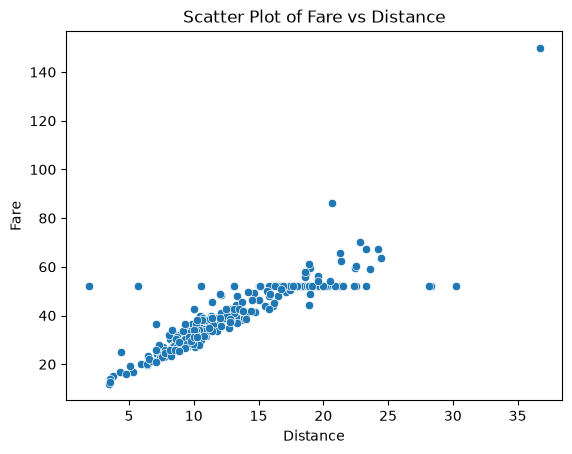

In [277]:
# Now I will check for the fare if it is normal or not, using a plot.
# At the first look, the fare looks normal, but I will check it using a plot.
# Compare the correlate between the fare and the distance,
# using a scatter plot.
# I am assume that it should be a linear relationship
# between the fare and the distance.

sns.scatterplot(data=taxis, x='distance', y='fare')
plt.xlabel('Distance')
plt.ylabel('Fare')
plt.title('Scatter Plot of Fare vs Distance')
plt.show()


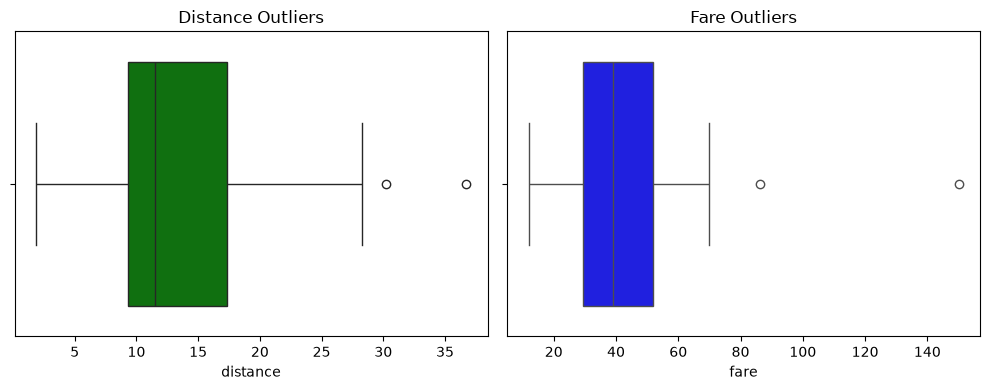

In [278]:
# Additional checking, for the outliner values need to remove,
# if we are going to use this datase for training a model, for example.
# Checking for the outlonder values

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(x=taxis['distance'], ax=axes[0], color='green')
axes[0].set_title('Distance Outliers')

sns.boxplot(x=taxis['fare'], ax=axes[1], color='blue')
axes[1].set_title('Fare Outliers')

plt.tight_layout()
plt.show()

In [279]:
# Checking for median and mean values of the fare and distance columns
print("Mean fare :", taxis['fare'].mean())
print("Median fare:", taxis['fare'].median())
print("Mode fare :", taxis['fare'].mode().values)   # shows the repeated value

Mean fare : 40.37
Median fare: 39.0
Mode fare : [52.]


### The scatter plot shows a clear and predictable regression trend.

I found that many rows have the same fare, around 52, which is unusual. I think the taxi meter is set to a fixed rate or is not working properly.

### My assessment: 2 points

### Task 3 questions
Answer these questions:
1. Does the fare look normally distributed? Why/why not?

2. How do the mean and median variables comparison tell this?

3. Are there outliers in the fare? Or anything else noteworthy?

### The fare looks normal compared to the distance.
### However, several rows are incorrect: trips have the same fare despite having different distances,
### and they all cluster around 52.

I can see that the mean (40.37) is close to the median (39.0), which means most of the fares are normal.

The mode fare, however, is a red flag. The most frequent fare is exactly 52—greater than both the mean and the median. That means a large number of trips are charged the same flat amount regardless of distance. In a normal taxi dataset, fares should vary continuously with distance rather than piling up at one exact number.

So overall, the data is not completely normal. While most rides look reasonable, there is an abnormal cluster of trips at exactly 52, which supports your suspicion of a flat fare or meter malfunction.

This reflects what I see in the plot view.

# Notes: I used AI to help me understand the "mode" value. The mode is the value that appears most frequently in a dataset.

### We have the outliner values for the fare. We can see them in the boxplot above.

## Task 4: Summaries (2 points)

- Calculate the average trip duration in minutes and add that to the dataframe. (I removed the word "first", since it makes me confused)

- Create a summary table showing:
  - average fare, average distance, average trip duration (in minutes), and  number of trips for each pickup borough.

- Answer the qustions.

**Assessment guide for task 4:**
- 0 points: not done or less than half done
- 1 point: not completely done but more than half done
- 2 points: completely done


In [280]:
# YOUR CODE HERE; ADD MORE CODE CELLS WHEN NEEDED
# create a new column duration, which is the difference
# between dropoff and pickup time
taxis['trip_duration_min'] = (
    taxis['dropoff'] - taxis['pickup']).dt.total_seconds(
    ) / 60  # duration in minutes

# The avg_trip_duration_min should be added to another summary table,
# It shoud noe be added to the taxis dataframe.
taxis.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough,trip_duration_min
22,2019-03-28 17:20:54,2019-03-28 17:55:57,1,9.82,31.5,8.31,5.76,49.87,yellow,credit card,LaGuardia Airport,Sutton Place/Turtle Bay North,Queens,Manhattan,35.050000
43,2019-03-27 19:39:16,2019-03-27 20:00:26,1,9.50,28.0,0.00,5.76,35.06,yellow,cash,LaGuardia Airport,Washington Heights South,Queens,Manhattan,21.166667
56,2019-03-05 17:57:00,2019-03-05 18:45:25,2,19.59,52.0,0.00,5.76,65.56,yellow,credit card,JFK Airport,Upper East Side North,Queens,Manhattan,48.416667
104,2019-03-28 13:29:48,2019-03-28 13:56:36,3,9.50,30.0,0.00,5.76,39.06,yellow,cash,Queensboro Hill,Midtown South,Queens,Manhattan,26.800000
111,2019-03-15 10:56:56,2019-03-15 11:37:02,1,11.93,39.5,9.71,5.76,58.27,yellow,credit card,Times Sq/Theatre District,LaGuardia Airport,Manhattan,Queens,40.100000


In [281]:
# Create a summary table showing:
# average fare, average distance, average trip duration (in minutes),
# and  number of trips for each pickup borough.

summary = taxis.groupby('pickup_borough').agg({
    'fare': 'mean',
    'distance': 'mean',
    'trip_duration_min': 'mean',
    'pickup': 'count'
})

summary

,fare,distance,trip_duration_min,pickup
pickup_borough,,,,
Bronx,41.075714,14.405714,37.347619,14
Brooklyn,50.034706,16.124118,50.430392,17
Manhattan,39.891356,13.003475,37.783475,118
Queens,39.708764,13.009494,35.185206,178


### My assessmentL 2 points

### Task 4 questions
Answer these questions:
1. Which borough has the highest average fare?

2. Which borough has the longest trips?

3. Which borough generates the most trips?


### My answer:

1. Brooklyn borough has the highest average fare = 50.03

2. Brooklyn borough has the longest trips = 16.12

3. Queens borough generates the most trips = 178


## Task 5: Scaling Numerical Data (2 points)

- Use StandardScaler to scale fare, distance and trip_duration_min.
- Create age_scaled, fare_scaled and trip_duration_min_scaled.
- Verify means and standard deviations after scaling.
- Answer the question.

**Assessment guide for task 5:**
- 0 points: not done or less than half done
- 1 point: not completely done but more than half done
- 2 points: completely done

In [282]:
# YOUR CODE HERE; ADD MORE CODE CELLS WHEN NEEDED
# Using the statistics from the summary table

scaler = StandardScaler()
scaled_summary = scaler.fit_transform(
  summary[['fare', 'distance', 'trip_duration_min']]
  )
new_summary = pd.DataFrame(
  scaled_summary, 
  columns=['fare', 'distance', 'trip_duration_min'], index=summary.index
  )

new_summary

,fare,distance,trip_duration_min
pickup_borough,,,
Bronx,-0.374289,0.210573,-0.473531
Brooklyn,1.718982,1.550687,1.708568
Manhattan,-0.651015,-0.882977,-0.400834
Queens,-0.693678,-0.878283,-0.834204


In [283]:
# - Create age_scaled, fare_scaled and trip_duration_min_scaled.
# There is no clumn named age in the dataset,
# so I will create only fare_scaled and trip_duration_min_scaled.

# Selecting the numerical columns to scale (note: taxis has no 'age' column,
# so we scale the columns the task names that actually exist)
cols_to_scale = ['fare', 'distance', 'trip_duration_min']

scaler = StandardScaler()

# fit_transform returns a numpy array; assign scaled values back as new columns
taxis[
  ['fare_scaled', 'distance_scaled', 'trip_duration_min_scaled']
  ] = scaler.fit_transform(
    taxis[cols_to_scale]
  )

taxis[['fare', 'distance', 'trip_duration_min',
      'fare_scaled', 'distance_scaled', 'trip_duration_min_scaled']].head()

,fare,distance,trip_duration_min,fare_scaled,distance_scaled,trip_duration_min_scaled
22,31.5,9.82,35.050000,-0.655044,-0.666109,-0.137927
43,28.0,9.50,21.166667,-0.913516,-0.728635,-1.115931
56,52.0,19.59,48.416667,0.858868,1.242909,0.803681
104,30.0,9.50,26.800000,-0.765817,-0.728635,-0.719094
111,39.5,11.93,40.100000,-0.064249,-0.253823,0.217818


In [284]:
# Before scaling, the mean and standard
# deviation of the columns are as follows:
print("Means before scaling:")
print(taxis[['fare', 'distance', 'trip_duration_min']].mean())
print("Standard deviations before scaling:")
print(taxis[['fare', 'distance', 'trip_duration_min']].std())

Means before scaling:
fare                 40.370000
distance             13.229021
trip_duration_min    37.007951
dtype: float64
Standard deviations before scaling:
fare                 13.561838
distance              5.125658
trip_duration_min    14.217330
dtype: float64


In [285]:
# StandardScaler gives mean ~ 0 and std ~ 1
print("Means after scaling:")
print(taxis[
  ['fare_scaled', 'distance_scaled', 'trip_duration_min_scaled']
  ].mean())

print("\nStandard deviations after scaling (ddof=0 to match StandardScaler):")
print(taxis[
  ['fare_scaled', 'distance_scaled', 'trip_duration_min_scaled']
  ].std(ddof=0))

Means after scaling:
fare_scaled                 1.738331e-16
distance_scaled             1.846977e-16
trip_duration_min_scaled    1.358071e-16
dtype: float64

Standard deviations after scaling (ddof=0 to match StandardScaler):
fare_scaled                 1.0
distance_scaled             1.0
trip_duration_min_scaled    1.0
dtype: float64


### After aplying the scandard scale, the Standard deviations should be 1.0

### My Assessment: 2 points 

### Task 5 question
Answer this question:
1. Why is the mean not (necessarily) precisely 0 and standard deviation not precisely 1?

### I used AI to help me answer this question
### Here is what I found

The mean of the scaled data is never exactly 0 because of finite floating-point precision. After centering and dividing, the residuals are on the order of machine epsilon (~1e-16), so mean() prints something like 3.7e-17 — effectively 0, but not exactly 0.

My reflection:

Because of the standard scaling formula and the use of a float variable, the exact value cannot reach 0.

## Task 6 Linear Regression (5 points)
- Use the `scikit-learn` to predict the taxi `fare` using two independent variables: `distance` and `trip_duration_min`.

- Get the intercept and also r2_score.

- Compare these two models:
  1. **Unscaled taxi data**
  2. **Scaled taxi data** (to compare feature importance/coefficients directly)

- Compare their intercepts and also r2_score.

- Plot both with the regression line.
- Answer the questions.

**Hints**:
1. Check out week 41 lecture slides and see how to do linear regression and get the intercept. Then find out how to get the r2_score.
2. Use these:
  - from sklearn.linear_model import LinearRegression
  - from sklearn.metrics import r2_score
3. Use these (in unscaled data, figure out the scaled data versions yourself):
  - X_unscaled = taxis_cleaned[["distance", "trip_duration_min"]]
  - y_unscaled = taxis_cleaned["fare"]


**Assessment guide for task 6:**
- 2 points from unscaled data model and plot (1 point from nice try; 0 points from mostly or totally missing)
- 2 points from scaled data model and plot (1 point from nice try; 0 points from mostly or totally missing)
- 1 point form answering the questions

In [286]:
# YOUR CODE HERE; ADD MORE CODE CELLS WHEN NEEDED

# Unscaled model
unscaled_model = LinearRegression()
unscaled_model.fit(taxis[["distance"]], taxis["trip_duration_min"])
print(f"Unscaled model intercept = {unscaled_model.intercept_}, " +
      f"coefficient = {unscaled_model.coef_}")

# Scaled model
scaled_model = LinearRegression()
scaled_model.fit(taxis[["distance_scaled"]], taxis["trip_duration_min_scaled"])
print(f"Scaled model intercept = {scaled_model.intercept_}, " +
      f"coefficient = {scaled_model.coef_}")

Unscaled model intercept = 13.36439351365641, coefficient = [1.78724917]
Scaled model intercept = 1.679857273828237e-17, coefficient = [0.64434238]


### My reflection: The intercept and the coefficient are differrent from saled vs unscaled models

Unscaled model intercept = 13.36439351365641, coefficient = [1.78724917]
Scaled model intercept = 1.679857273828237e-17, coefficient = [0.64434238]

In [287]:
# Unscaled model
unscaled_pred = unscaled_model.predict(taxis[["distance"]])
unscaled_r2 = r2_score(taxis["trip_duration_min"], unscaled_pred)

# Scaled model (scored on the scaled target)
scaled_pred = scaled_model.predict(taxis[["distance_scaled"]])
scaled_r2 = r2_score(taxis["trip_duration_min_scaled"], scaled_pred)

print(f"Unscaled R² = {unscaled_r2:.4f}")
print(f"Scaled R²   = {scaled_r2:.4f}")

Unscaled R² = 0.4152
Scaled R²   = 0.4152


In [288]:
# I can see that the both R2 values (0.4152) are the same,
# despite of the 2 intercept and cofficient are different
# from the two models.

# My Assessment: 5 points

### Task 6 questions
Answer these questions:
1. Are the r2_score of the two models same or different? Why?

2. What is the intercept of the model using scaled data? Why?

3. When you compare the unscaled and scaled model's plots, what do you notice? How should they be interpreted?


## My Answers
1. Yes, the R² of the two models is the same (0.4152).
2. The intercept of the scaled model will be smaller, because the standardized data is now smaller and centers around the mean value.
3. What I've learned using AI support:

- Scaling changes the numerical values of intercept_ and coef_ and the visual appearance on shared axes.
- Scaling does not change the fitted relationship, predictions (when converted back), residuals, or R².
- Use the unscaled model for interpretation in business units (minutes per mile/km). Use the scaled model only when comparing relative feature importance across multiple predictors.

## Part 7: Data Visualization (4 points)

- Create and interpret these four visualizations:
  1. Scatterplot distance vs. fare
  2. Distance distribution
  3. Trips by hour
  4. Average fare by borough

- Use propriate titles and axis names
- Interprete the plots (briefly).

**Assessment guide for task 7:**
- 1 point per plot + interpretation if well done according to instructions
- 0.5 points per plot: nice try
- 0 points: mostly or completely not done


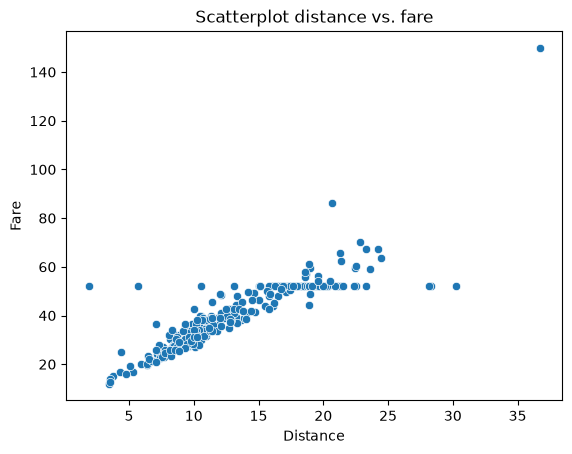

In [289]:
# YOUR CODE HERE; ADD MORE CODE CELLS WHEN NEEDED
# Scatter plot: Distance vs fare
axes = sns.scatterplot(taxis, x="distance", y="fare")
axes.set_title("Scatterplot distance vs. fare")
axes.set_xlabel("Distance")
axes.set_ylabel("Fare")
plt.show()

In [290]:
# My reflection: there are still errors in the data (as discussed above)
# But this data is now correct and clean,
# and it can be used to train the model (linear regression)

<Axes: xlabel='distance', ylabel='Count'>

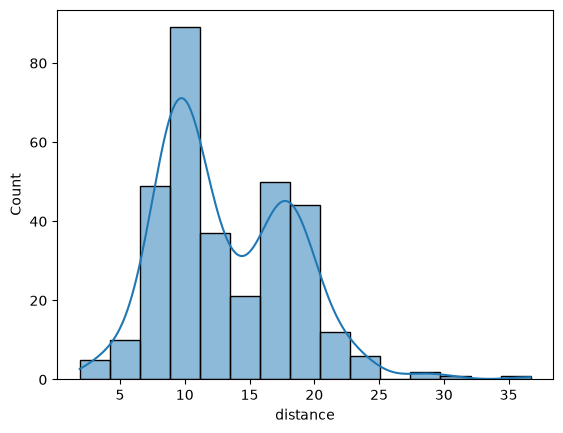

In [291]:
# For distance distribution, use the historygram
sns.histplot(data=taxis, x="distance", kde=True)

In [292]:
## Take a look at the histogram: people traveling 
# a distance of around 10 is very popular

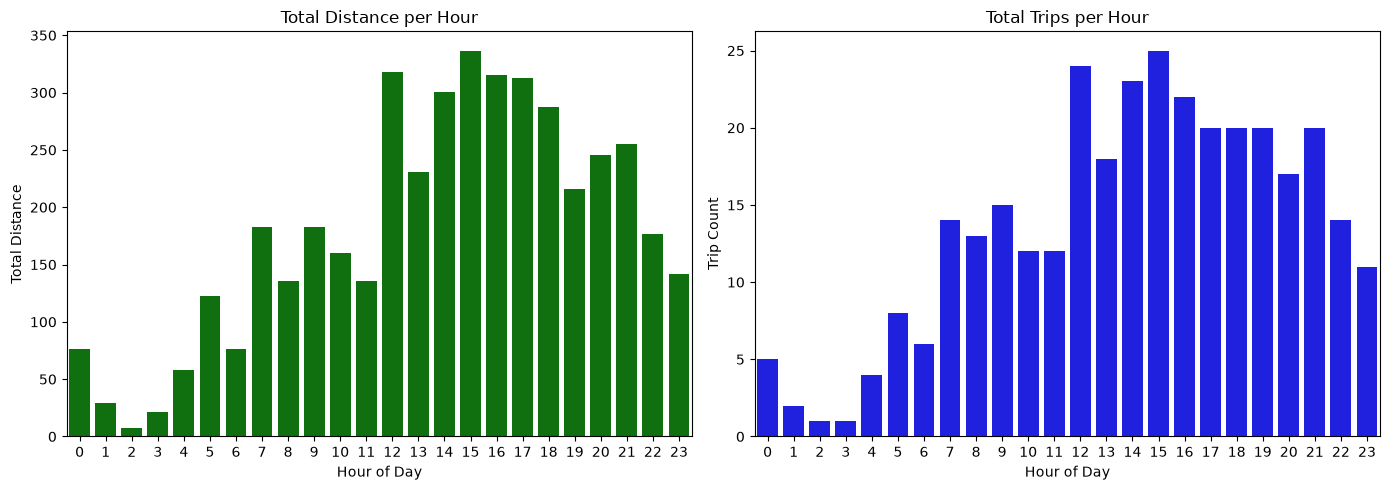

In [293]:
# To plot a chart of trips by hour, the simplest way is to create
# a new DataFrame with the hour extracted from pickup.
# Then use that data to plot a bar chart.

# I think the value of a trip is based on distance and total fare,
# but distance seems to be the primary metric.
# So, I will plot distance by hour in the bar chart.

hour_df = taxis[["pickup", "distance"]].copy()
hour_df["hour"] = hour_df["pickup"].dt.hour

hour_sum = hour_df.groupby("hour")["distance"].agg("sum").reset_index()

# Now plot the charts side by side using subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=hour_sum, x="hour", y="distance", ax=axes[0], color="green")
axes[0].set_title("Total Distance per Hour")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Total Distance")

# From another perspective, if the taxi company wants to count the number of trips per hour,
# I will plot the chart this way:

hour_count = hour_df.groupby("hour").size().reset_index(name="trip_count")

sns.barplot(data=hour_count, x="hour", y="trip_count", ax=axes[1], color="blue")
axes[1].set_title("Total Trips per Hour")
axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Trip Count")

plt.tight_layout()
plt.show()



### My reflection:
People seem to travel by taxi the most between 12:00 and 21:00.
Fewer people use taxis between 1:00 and 3:00.

Text(0, 0.5, 'Total Fare')

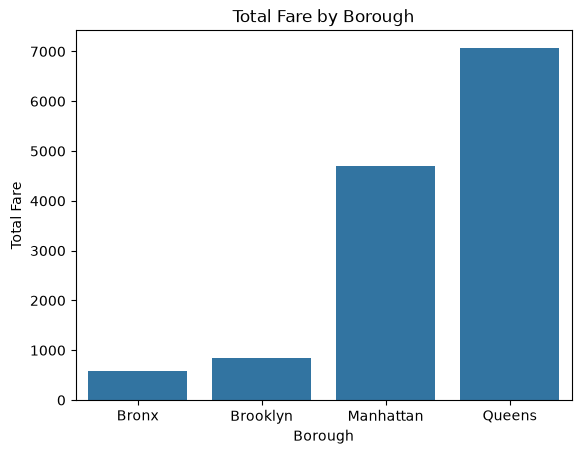

In [294]:
# Average fare by borough (pickup)
borough_vs_fare = (
  taxis[["pickup_borough", "fare"]]
  .groupby("pickup_borough", as_index=False)["fare"]
  .agg("sum")
  .rename(columns={"pickup_borough": "borough"})
)

ax = sns.barplot(
    data=borough_vs_fare,
    x="borough",
    y="fare",
)
ax.set_title("Total Fare by Borough")
ax.set_xlabel("Borough")
ax.set_ylabel("Total Fare")


In [295]:
## As I can see, Queens has the highest fare

### Part 7 plots' interpretations here
  1. Scatterplot distance vs. fare:

  2. Distance distribution:
  
  3. Trips by hour:
  
  4. Average fare by borough:

### My reflection and answers:

1. **Scatterplot of distance vs. fare:** The data can be used to train a linear regression model (although it still contains some inaccurate data, it is usable).
2. **Distance distribution:** People tend to take trips with a distance of around 10.
3. **Trips by hour:** Most trips occur during the daytime, around 07:00 to 23:00, with peak values around 15:00 to 17:00.
4. **Total fare by borough:** Queens has the highest fare (up to 7,000), while the Bronx has the lowest fare (around 600).

### Self assessment: 4 points

## Task: AI statement (mandatory, missing AI statement (if AI used) is considered fraud)

- Describe here, how did you use AI in this assignment
- Describe also, if you did not use AI in this assignment


In [296]:
# I used AI (Gemini) to correct grammar and syntax errors.
# I also used AI to learn about the model.
# All the directions and ideas came from my own mind, not AI. I asked AI, 
# but it only gave me ridiculous suggestions.

## Task: Self assessment (mandatory, missing self assessment causes -1 point)

- Check the task specific assessment instructions.
- How many points would you give yourself? ANSWER HERE: 19 points
- If missing points, why are they missing and which task is missing points? ANSWER HERE:I didn't miss any. Just one thing" column "age" does not exit in the dataframe.


## Homework return (mandatory)

- File > Save and Export Notebook As > HTML
- Then take a look the produced HTML that it looks ok and readable (= it looks like this Jupyter notebook looks, so no html source code etc. shall be visible)
- Return to Itslearning, only the html document is returned, *not* the .ipynb
